In [51]:
import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [52]:
df=pd.read_csv("/content/car_dataset.csv")


In [53]:
df.info()
display(df.head())
display(df.tail())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_id            180 non-null    int64  
 1   brand             180 non-null    object 
 2   model             180 non-null    object 
 3   year              180 non-null    int64  
 4   segment           180 non-null    object 
 5   body_type         180 non-null    object 
 6   fuel_type         180 non-null    object 
 7   transmission      180 non-null    object 
 8   engine_cc         180 non-null    int64  
 9   power_hp          180 non-null    int64  
 10  fuel_economy_mpg  180 non-null    float64
 11  seats             180 non-null    int64  
 12  km_driven         180 non-null    int64  
 13  num_owners        180 non-null    int64  
 14  condition         180 non-null    object 
 15  accident_history  180 non-null    int64  
 16  color             180 non-null    object 
 1

,car_id,brand,model,year,segment,body_type,fuel_type,transmission,engine_cc,power_hp,fuel_economy_mpg,seats,km_driven,num_owners,condition,accident_history,color,city,price_usd
0,1,Hyundai,i20,2012,Hatchback,Hatchback,Diesel,Manual,1320,78,42.0,5,120639,1,Good,0,Brown,Mumbai,1460.0
1,2,Volkswagen,Polo,2021,Hatchback,Hatchback,Petrol,Automatic,1000,116,35.9,5,39084,1,Good,0,Blue,Bengaluru,7710.0
2,3,Volkswagen,Golf,2020,Hatchback,Hatchback,Petrol,Automatic,1400,136,32.7,5,39194,1,Good,0,Black,Kolkata,11100.0
3,4,Tata,Nexon,2019,SUV,SUV,Diesel,Manual,1320,115,30.5,5,69792,2,Good,0,Blue,Mumbai,4240.0
4,5,Mahindra,Scorpio,2024,SUV,SUV,Diesel,Manual,2420,148,23.0,7,9464,1,Good,0,Green,Chennai,17960.0


,car_id,brand,model,year,segment,body_type,fuel_type,transmission,engine_cc,power_hp,fuel_economy_mpg,seats,km_driven,num_owners,condition,accident_history,color,city,price_usd
175,176,Chevrolet,Malibu,2021,Midsize,Sedan,Petrol,Automatic,1500,154,29.9,5,39829,2,Excellent,0,Brown,Kolkata,13740.0
176,177,Chevrolet,Silverado,2013,Truck,Pickup,Diesel,Automatic,5830,407,21.9,5,94700,1,Good,0,Black,Delhi,5900.0
177,178,Nissan,Rogue,2023,SUV,SUV,Petrol,Manual,2500,186,30.7,5,18977,1,Good,0,Silver,Bengaluru,18960.0
178,179,Hyundai,Tucson,2019,SUV,SUV,CNG,Automatic,2500,181,29.5,5,98586,1,Fair,0,Blue,Hyderabad,7730.0
179,180,Maruti Suzuki,Ertiga,2023,MPV,MPV,CNG,Automatic,1500,97,25.7,7,29724,1,Fair,0,Black,Mumbai,7970.0


In [54]:

df.columns = [col.strip().lower() for col in df.columns]

# Rename specific columns if they differ slightly to standard names
df.rename(columns={'car_name': 'brand', 'kms_driven': 'km_driven', 'selling_price': 'price'}, inplace=True)


if 'brand' in df.columns:
    df['brand'] = df['brand'].apply(lambda x: str(x).split(' ')[0])


print(f"Duplicate rows found: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)


df['car_age'] = 2026 - df['year']


num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()


for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].mode()[0], inplace=True)


print(f"Dataset shape after cleaning: {df.shape}")
print(f"Remaining null values: {df.isnull().sum().sum()}")

Duplicate rows found: 0
Dataset shape after cleaning: (180, 20)
Remaining null values: 0


In [55]:
# Summary statistics for numerical variables
display(df.describe().T)

# Summary statistics for categorical variables
display(df.describe(include=['object']).T)

,count,mean,std,min,25%,50%,75%,max
car_id,180.0,90.500000,52.105662,1.0,45.75,90.5,135.250,180.0
year,180.0,2017.877778,3.724681,2012.0,2015.00,2018.0,2021.000,2024.0
engine_cc,180.0,2188.611111,1100.190316,0.0,1500.00,2000.0,2500.000,5830.0
power_hp,180.0,202.811111,96.445764,69.0,123.00,183.0,267.000,478.0
fuel_economy_mpg,180.0,31.689444,14.532124,17.8,25.80,30.0,33.425,132.6
seats,180.0,5.166667,0.611802,4.0,5.00,5.0,5.000,7.0
km_driven,180.0,90860.916667,58095.279847,8594.0,47279.75,81022.5,127994.500,263178.0
num_owners,180.0,1.950000,0.987492,1.0,1.00,2.0,2.250,4.0
accident_history,180.0,0.172222,0.378627,0.0,0.00,0.0,0.000,1.0
price_usd,180.0,10326.888889,9180.158729,1060.0,3242.50,7375.0,15765.000,50950.0


,count,unique,top,freq
brand,180,17,Volkswagen,19
model,180,39,Silverado,9
segment,180,9,SUV,57
body_type,180,6,SUV,76
fuel_type,180,5,Petrol,120
transmission,180,2,Automatic,125
condition,180,4,Good,87
color,180,8,Black,25
city,180,8,Delhi,29


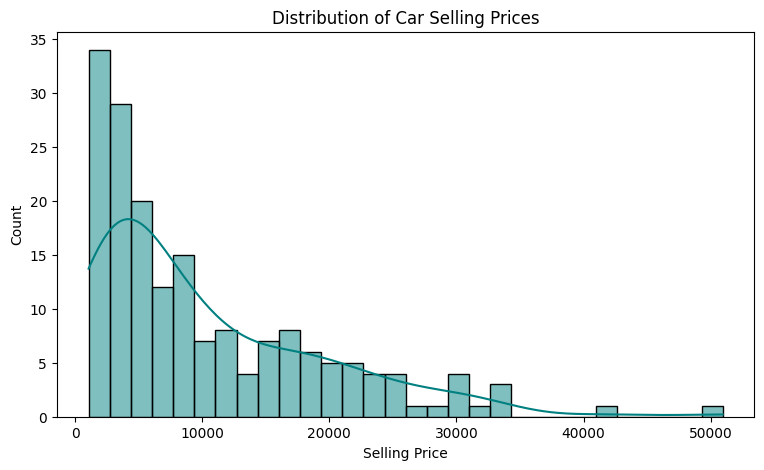

In [56]:
plt.figure(figsize=(9, 5))

sns.histplot(df['price_usd'], bins=30, kde=True, color='teal')
plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Count')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

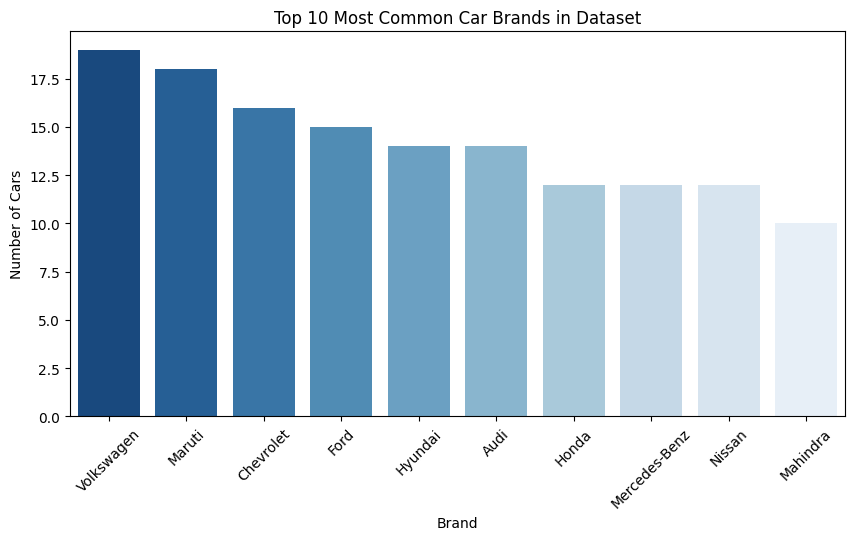

In [57]:
plt.figure(figsize=(10, 5))
top_brands = df['brand'].value_counts().head(10)
sns.barplot(x=top_brands.index, y=top_brands.values, palette='Blues_r')
plt.title('Top 10 Most Common Car Brands in Dataset')
plt.xlabel('Brand')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.show()

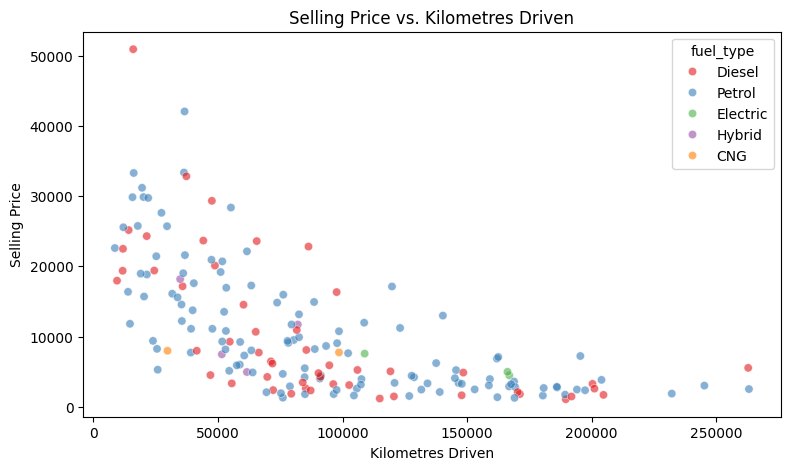

In [58]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x='km_driven', y='price_usd', hue='fuel_type' if 'fuel_type' in df.columns else 'fuel', data=df, alpha=0.6, palette='Set1')
plt.title('Selling Price vs. Kilometres Driven')
plt.xlabel('Kilometres Driven')
plt.ylabel('Selling Price')
plt.ticklabel_format(style='plain', axis='both')
plt.show()

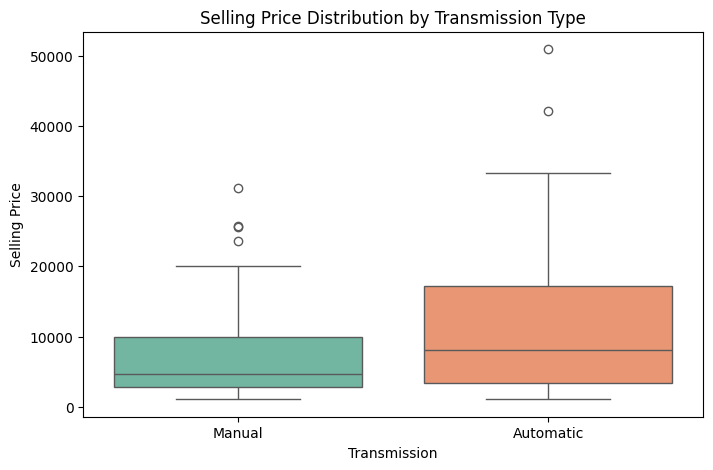

In [59]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='transmission', y='price_usd', data=df, palette='Set2')
plt.title('Selling Price Distribution by Transmission Type')
plt.xlabel('Transmission')
plt.ylabel('Selling Price')
plt.ticklabel_format(style='plain', axis='y')
plt.show()

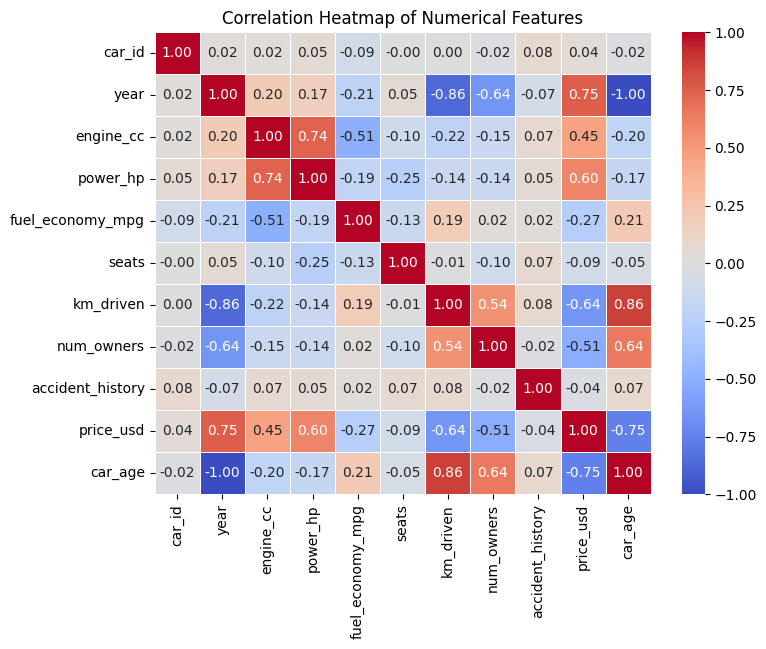

In [60]:
plt.figure(figsize=(8, 6))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

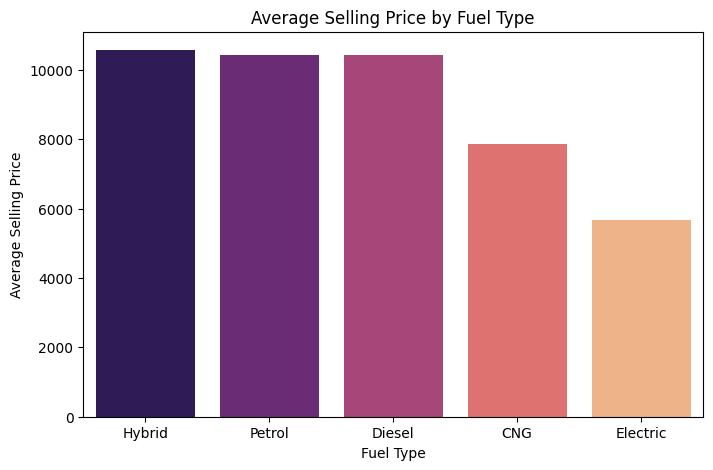

In [61]:
plt.figure(figsize=(8, 5))
fuel_col = 'fuel_type' if 'fuel_type' in df.columns else 'fuel'
fuel_price = df.groupby(fuel_col)['price_usd'].mean().sort_values(ascending=False)
sns.barplot(x=fuel_price.index, y=fuel_price.values, palette='magma')
plt.title('Average Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price')
plt.ticklabel_format(style='plain', axis='y')
plt.show()